<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/07_decision_errors_andrew.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/notebooks/07_decision_errors_andrew.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 3: from a predicted rating to a decision, and where the model goes wrong

*AI-assisted: every code and markdown cell was generated with Claude (Opus 5.5) on 2026-11-09 and reviewed, run and edited by Andrew Reicin. None of this text is for the slides or report.*

A producer decides whether to make a game, using the model's predicted rating. Steps: set costs for each mistake, choose the cutoff on validation rows, compare with making every game or none, test other cost ratios, try a classifier, and look at which games the model gets wrong.

Rows and model follow notebook 04 until Tasks 1 and 10 are in; each is set in one cell (sections 1 and 2).

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Imports; reviewed and edited by Andrew Reicin.
# --- Andrew Reicin: Task 3, turning predicted ratings into a decision with error costs, and diagnosing the model's errors ---
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Every code and markdown cell in this notebook was generated with Claude and reviewed, run and edited by Andrew Reicin.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, precision_score, recall_score, ConfusionMatrixDisplay

# Figures go to the repository's figures folder when run inside the repository, otherwise next to the notebook.
FIG_DIR = "../figures" if os.path.isdir("../figures") else "."

## 1. Rows and split

Same rows and 70/30 split (random state 1) as notebook 04.

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Load data and define the rows; reviewed and edited by Andrew Reicin.
BASE = "https://raw.githubusercontent.com/24sahil25-source/BA305-BoardGameGeek-Fall2026/main/data/"
games = pd.read_csv(BASE + "bgg_clean.csv")

# ROWS: notebook 04's rows, games with every input known. Replace with Task 1's choice on missing values once it is posted.
numeric_cols = ["yearpublished", "minplayers", "maxplayers", "minplaytime", "maxplaytime", "minage", "n_mechanics", "n_categories"]
data = games.dropna(subset=numeric_cols + ["boardgamemechanic", "boardgamecategory", "average"]).reset_index(drop=True)

train_df, test_df = train_test_split(data, test_size=0.3, random_state=1)
y_train = train_df["average"]
y_test = test_df["average"]
print("games used:", len(data), "| training rows:", len(train_df), "| test rows:", len(test_df))

games used: 17982 | training rows: 12587 | test rows: 5395


In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Build the inputs exactly as notebook 04 does; reviewed and edited by Andrew Reicin.
# The 20 most common mechanics and 15 most common categories, counted on the training rows only.
top_mech = train_df["boardgamemechanic"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(20).index
top_cat = train_df["boardgamecategory"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(15).index

# Inputs for any set of rows: log10 of the skewed counts and times, plus 0/1 columns for the kept mechanics and categories.
def build_inputs(frame):
    X = frame[numeric_cols].copy()
    for col in ["minplayers", "maxplayers", "minplaytime", "maxplaytime"]:
        X[col] = np.log10(X[col])
    mech = frame["boardgamemechanic"].str.get_dummies(sep="|").reindex(columns=top_mech, fill_value=0).add_prefix("mech_")
    cat = frame["boardgamecategory"].str.get_dummies(sep="|").reindex(columns=top_cat, fill_value=0).add_prefix("cat_")
    return pd.concat([X, mech, cat], axis=1)

X_train = build_inputs(train_df)
X_test = build_inputs(test_df)
print("inputs:", X_train.shape[1], "columns")

# Leakage check: none of the post-release columns is an input.
post_release = ["rank", "bayes_average", "users_rated", "owned", "trading", "wanting", "wishing"]
print("post-release columns among the inputs:", [c for c in post_release if c in X_train.columns])

inputs: 43 columns
post-release columns among the inputs: []


## 2. The model

Notebook 04's tuned regression tree (max_depth 10, min_samples_leaf 50).

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Fit the model and score it next to the dummy baseline; reviewed and edited by Andrew Reicin.
# MODEL: replace make_model() with Task 10's final model once it is chosen.
def make_model():
    return DecisionTreeRegressor(max_depth=10, min_samples_leaf=50, random_state=0)

model = make_model().fit(X_train, y_train)
pred_test = model.predict(X_test)

dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)

print("Regression tree:  RMSE", round(np.sqrt(mean_squared_error(y_test, pred_test)), 3),
      "| MAE", round(mean_absolute_error(y_test, pred_test), 3), "| R2", round(r2_score(y_test, pred_test), 3))
print("Dummy (mean):     RMSE", round(np.sqrt(mean_squared_error(y_test, dummy_pred)), 3),
      "| MAE", round(mean_absolute_error(y_test, dummy_pred), 3), "| R2", round(r2_score(y_test, dummy_pred), 3))

Regression tree:  RMSE 0.684 | MAE 0.522 | R2 0.425
Dummy (mean):     RMSE 0.903 | MAE 0.709 | R2 -0.0


Matches notebook 04 (test RMSE 0.684 vs 0.903 for the dummy), so the setup is the same.

## 3. The decision and its costs

- **Decision:** a producer decides, before release, whether to make a game.
- **Hit:** actual average rating of 7.0 or higher (about the top quarter).
- **Flop (made, not a hit):** development and a print run spent on a game that does not sell. Cost 3.
- **Missed hit (not made, was a hit):** profit not earned. Cost 1.

The costs are hypothetical; section 6 tests other ratios.

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Hit label and cost function, in the style of Session 19's oxygen_cost; reviewed and edited by Andrew Reicin.
HIT = 7.0   # actual average rating that counts as a hit

# 1 = hit, 0 = not a hit
hit_train = np.where(y_train >= HIT, 1, 0)
hit_test = np.where(y_test >= HIT, 1, 0)
print("share of hits: training rows", round(hit_train.mean(), 3), "| test rows", round(hit_test.mean(), 3))

# Total cost of a production decision.
#   produce: 1 if the producer makes the game, 0 if it passes;  hit: 1 if the game turned out to be a hit
#   flop_cost: cost of each game made that was not a hit;  miss_cost: cost of each hit that was passed over
def decision_cost(produce, hit, flop_cost=3, miss_cost=1):
    produce = np.asarray(produce)
    hit = np.asarray(hit)
    flops = ((produce == 1) & (hit == 0)).sum()     # made, not a hit
    missed = ((produce == 0) & (hit == 1)).sum()    # passed, was a hit
    return flop_cost * flops + miss_cost * missed

share of hits: training rows 0.275 | test rows 0.282


## 4. Choosing the cutoff on validation rows

Rule: make the game if its predicted rating is at least the cutoff. The cutoff is chosen on validation rows (30% of the training rows, as in Session 17), never on the test rows.

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Hold out validation rows from the training rows; reviewed and edited by Andrew Reicin.
X_fit, X_valid, y_fit, y_valid = train_test_split(X_train, y_train, test_size=0.3, random_state=1)
hit_valid = np.where(y_valid >= HIT, 1, 0)

valid_model = make_model().fit(X_fit, y_fit)
pred_valid = valid_model.predict(X_valid)
print("fitting rows:", len(X_fit), "| validation rows:", len(X_valid))

fitting rows: 8810 | validation rows: 3777


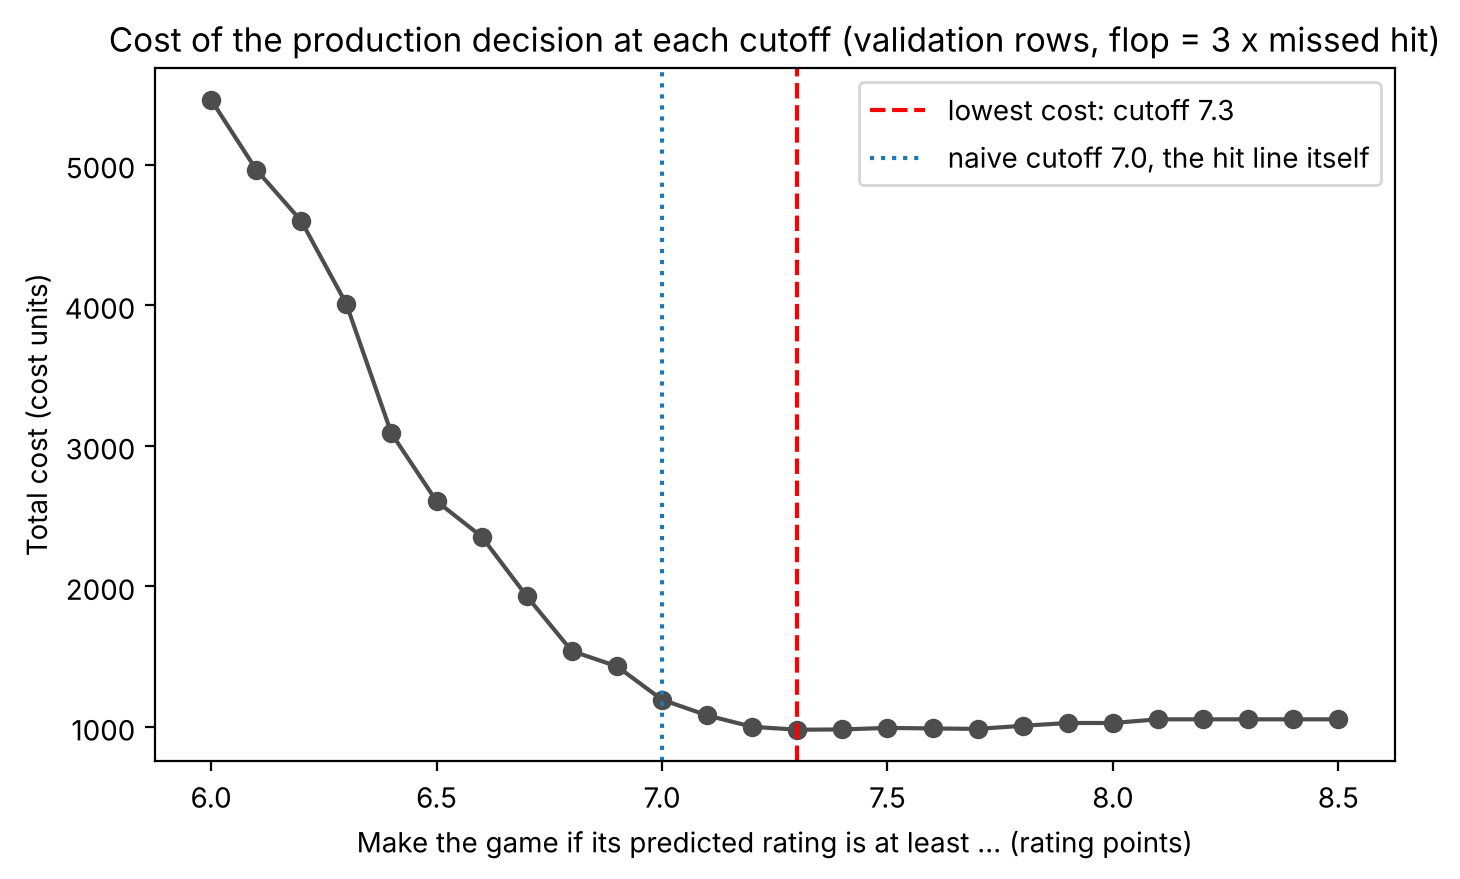

Lowest cost = 980 | best cutoff = 7.3


In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Try every cutoff and record its cost on the validation rows; reviewed and edited by Andrew Reicin.
cutoff_grid = np.round(np.arange(6.0, 8.51, 0.1), 1)
costs = []
for cutoff in cutoff_grid:
    produce = np.where(pred_valid >= cutoff, 1, 0)
    costs.append(decision_cost(produce, hit_valid))

best_idx = np.argmin(costs)
best_cut = cutoff_grid[best_idx]

plt.figure(figsize=(8, 4.5))
plt.plot(cutoff_grid, costs, marker="o", color="0.3")
plt.axvline(x=best_cut, color="red", linestyle="--", label=f"lowest cost: cutoff {best_cut}")
plt.axvline(x=HIT, color="tab:blue", linestyle=":", label=f"naive cutoff {HIT}, the hit line itself")
plt.title("Cost of the production decision at each cutoff (validation rows, flop = 3 x missed hit)")
plt.xlabel("Make the game if its predicted rating is at least ... (rating points)")
plt.ylabel("Total cost (cost units)")
plt.legend()
plt.savefig(os.path.join(FIG_DIR, "07_cost_by_cutoff.png"), dpi=300, bbox_inches="tight")
plt.show()
print("Lowest cost =", costs[best_idx], "| best cutoff =", best_cut)

Lowest cost at a cutoff of **7.3**, above the 7.0 hit line, because flops cost more.

## 5. The model against policies that use no model

Scored once on the test rows.

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Compare decision policies on the test rows; reviewed and edited by Andrew Reicin.
produce_model = np.where(pred_test >= best_cut, 1, 0)
produce_naive = np.where(pred_test >= HIT, 1, 0)
produce_all = np.ones(len(hit_test))
produce_none = np.zeros(len(hit_test))

rows = []
for name, produce in [(f"Model, cutoff {best_cut} (chosen)", produce_model), (f"Model, naive cutoff {HIT}", produce_naive),
                    ("Make every game", produce_all), ("Make no game", produce_none)]:
    rows.append({"policy": name,
                 "total cost": decision_cost(produce, hit_test),
                 "games made": int(produce.sum()),
                 "flops made": int(((produce == 1) & (hit_test == 0)).sum()),
                 "hits missed": int(((produce == 0) & (hit_test == 1)).sum()),
                 "precision": precision_score(hit_test, produce, zero_division=0),
                 "recall": recall_score(hit_test, produce)})
policy_table = pd.DataFrame(rows).set_index("policy").sort_values("total cost")
policy_table.round(3)

,total cost,games made,flops made,hits missed,precision,recall
policy,,,,,,
"Model, cutoff 7.3 (chosen)",1357,485,80,1117,0.835,0.266
Make no game,1522,0,0,1522,0.000,0.000
"Model, naive cutoff 7.0",1692,1098,317,741,0.711,0.513
Make every game,11619,5395,3873,0,0.282,1.000


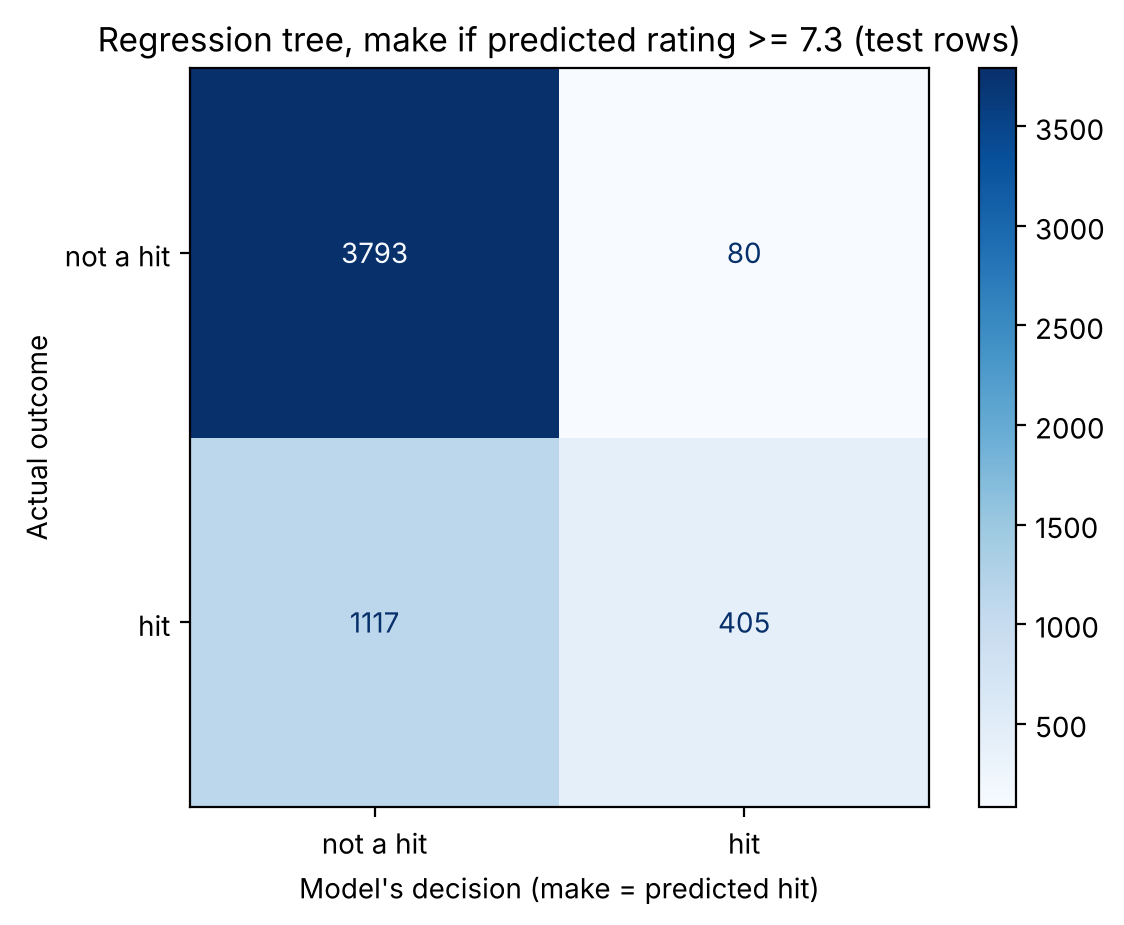

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Confusion matrix of the chosen policy on the test rows; reviewed and edited by Andrew Reicin.
ConfusionMatrixDisplay.from_predictions(hit_test, produce_model, display_labels=["not a hit", "hit"], cmap="Blues")
plt.title(f"Regression tree, make if predicted rating >= {best_cut} (test rows)")
plt.xlabel("Model's decision (make = predicted hit)")
plt.ylabel("Actual outcome")
plt.savefig(os.path.join(FIG_DIR, "07_confusion_matrix.png"), dpi=300, bbox_inches="tight")
plt.show()

Model at 7.3: cost 1,357, vs 1,522 for making no game and 11,619 for making every game. Precision 0.84, recall 0.27. The naive 7.0 cutoff (1,692) does worse than making no game.

## 6. Other cost ratios

The cutoff is re-chosen on the validation rows for each ratio, then scored on the test rows.

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Sensitivity of the cutoff and the winning policy to the cost ratio; reviewed and edited by Andrew Reicin.
rows = []
for flop_cost, miss_cost in [(1, 3), (1, 1), (2, 1), (3, 1), (5, 1)]:
    # choose the cutoff on the validation rows under this ratio
    costs_r = [decision_cost(np.where(pred_valid >= c, 1, 0), hit_valid, flop_cost, miss_cost) for c in cutoff_grid]
    cut_r = cutoff_grid[np.argmin(costs_r)]
    # score it on the test rows, next to the two no-model policies
    model_cost = decision_cost(np.where(pred_test >= cut_r, 1, 0), hit_test, flop_cost, miss_cost)
    all_cost = decision_cost(produce_all, hit_test, flop_cost, miss_cost)
    none_cost = decision_cost(produce_none, hit_test, flop_cost, miss_cost)
    rows.append({"flop : missed hit": f"{flop_cost} : {miss_cost}", "chosen cutoff": cut_r, "model": model_cost,
                 "make every game": all_cost, "make no game": none_cost,
                 "model saves vs best no-model policy": 1 - model_cost / min(all_cost, none_cost)})
pd.DataFrame(rows).set_index("flop : missed hit").round(3)

,chosen cutoff,model,make every game,make no game,model saves vs best no-model policy
flop : missed hit,,,,,
1 : 3,6.6,1987,3873,4566,0.487
1 : 1,7.0,1058,3873,1522,0.305
2 : 1,7.2,1245,7746,1522,0.182
3 : 1,7.3,1357,11619,1522,0.108
5 : 1,7.7,1450,19365,1522,0.047


The cutoff rises from 6.6 to 7.7 as flops get costlier. The model beats both no-model policies at every ratio, by 49% down to 5%.

## 7. Predicting the category directly

Same hit / not-hit label, with a decision tree classifier. About 27% of games are hits, so accuracy is not used; `class_weight="balanced"` handles the imbalance (Session 19), the tree is tuned by ROC AUC, and the probability cutoff is chosen by the same cost on the same validation rows.

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Dummy classifier: the accuracy trap; reviewed and edited by Andrew Reicin.
dummy_clf = DummyClassifier(strategy="most_frequent").fit(X_train, hit_train)
dummy_produce = dummy_clf.predict(X_test)
print("DummyClassifier (always 'not a hit'): accuracy", round((dummy_produce == hit_test).mean(), 3),
      "| recall", recall_score(hit_test, dummy_produce), "| cost", decision_cost(dummy_produce, hit_test))

DummyClassifier (always 'not a hit'): accuracy 0.718 | recall 0.0 | cost 1522


In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Tune the classifier; reviewed and edited by Andrew Reicin.
param_grid = {"max_depth": [3, 5, 8, 10, 12, 15], "min_samples_leaf": [20, 50, 100, 200, 400]}
search = GridSearchCV(DecisionTreeClassifier(class_weight="balanced", random_state=0), param_grid,
                      cv=KFold(n_splits=5, shuffle=True, random_state=0), scoring="roc_auc").fit(X_train, hit_train)
print("Best settings:", search.best_params_, "| cross-validated ROC AUC:", round(search.best_score_, 3))
pd.DataFrame(search.cv_results_).pivot(index="param_max_depth", columns="param_min_samples_leaf", values="mean_test_score").round(3)

Best settings: {'max_depth': 10, 'min_samples_leaf': 100} | cross-validated ROC AUC: 0.841


param_min_samples_leaf,20,50,100,200,400
param_max_depth,,,,,
3,0.792,0.792,0.792,0.792,0.790
5,0.827,0.827,0.828,0.823,0.809
8,0.836,0.839,0.841,0.829,0.811
10,0.832,0.840,0.841,0.829,0.811
12,0.828,0.839,0.841,0.829,0.811
15,0.827,0.839,0.841,0.829,0.811


First sweep (0.30 to 0.90) had its lowest cost at 0.90, the edge of the range, so the second sweep widens it to 0.98.

First sweep 0.30-0.90: lowest cost at 0.9


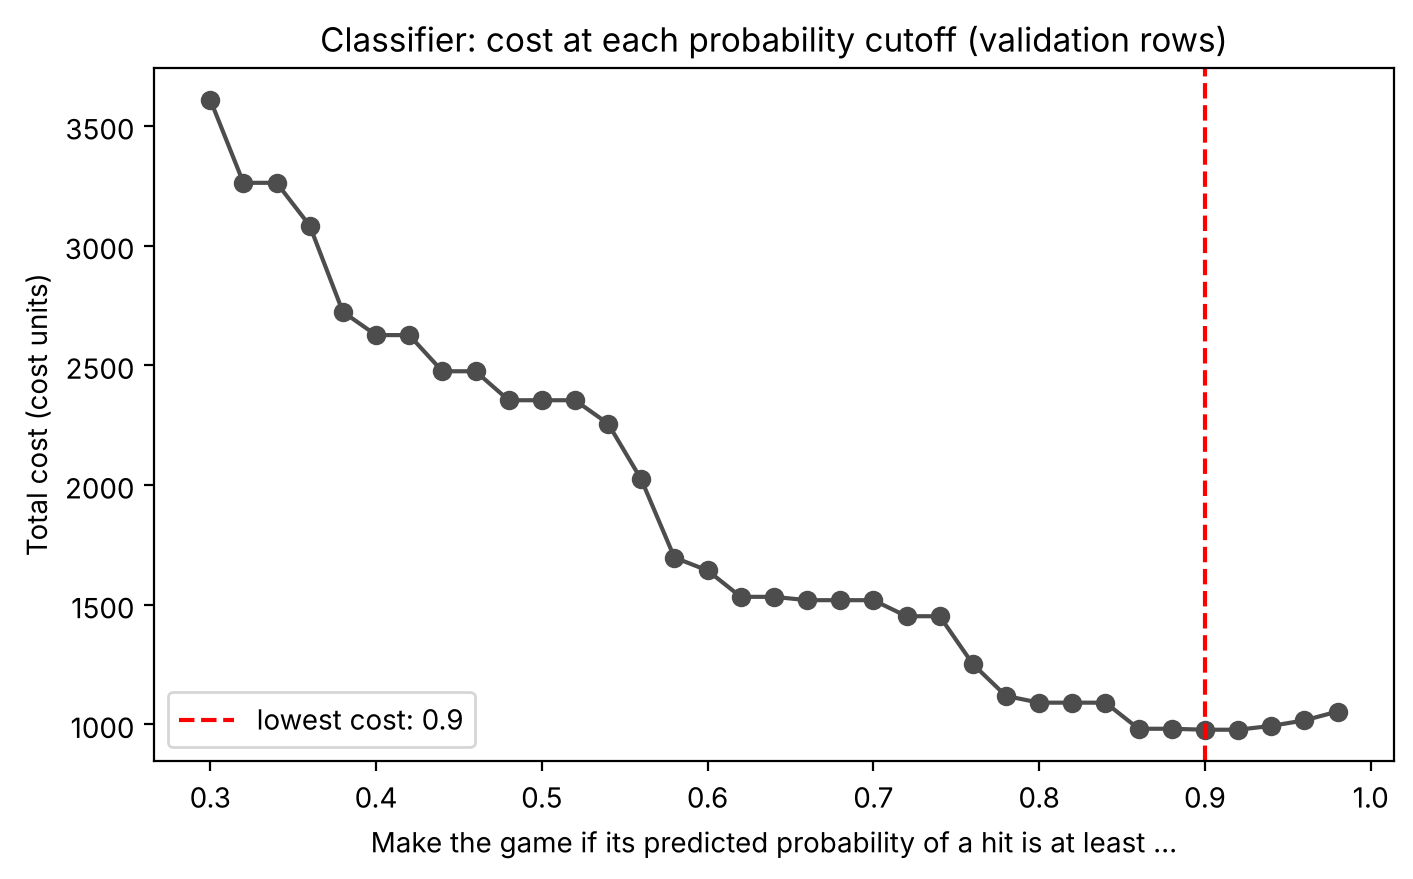

Best probability cutoff = 0.9


In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Choose the probability cutoff on the validation rows; reviewed and edited by Andrew Reicin.
hit_fit = np.where(y_fit >= HIT, 1, 0)
valid_clf = DecisionTreeClassifier(class_weight="balanced", random_state=0, **search.best_params_).fit(X_fit, hit_fit)
prob_valid = valid_clf.predict_proba(X_valid)[:, 1]

# First sweep, 0.30 to 0.90
first_grid = np.round(np.arange(0.30, 0.91, 0.05), 2)
first_costs = [decision_cost(np.where(prob_valid >= c, 1, 0), hit_valid) for c in first_grid]
print("First sweep 0.30-0.90: lowest cost at", first_grid[np.argmin(first_costs)])

# Wider, finer sweep, 0.30 to 0.98
prob_grid = np.round(np.arange(0.30, 0.99, 0.02), 2)
prob_costs = [decision_cost(np.where(prob_valid >= c, 1, 0), hit_valid) for c in prob_grid]
best_p = prob_grid[np.argmin(prob_costs)]

plt.figure(figsize=(8, 4.5))
plt.plot(prob_grid, prob_costs, marker="o", color="0.3")
plt.axvline(x=best_p, color="red", linestyle="--", label=f"lowest cost: {best_p}")
plt.title("Classifier: cost at each probability cutoff (validation rows)")
plt.xlabel("Make the game if its predicted probability of a hit is at least ...")
plt.ylabel("Total cost (cost units)")
plt.legend()
plt.show()
print("Best probability cutoff =", best_p)

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Score the classifier once on the test rows, next to the regression approach; reviewed and edited by Andrew Reicin.
clf = search.best_estimator_     # refitted by GridSearchCV on all training rows
produce_clf = np.where(clf.predict_proba(X_test)[:, 1] >= best_p, 1, 0)

rows = []
for name, produce in [(f"Regression tree, rating cutoff {best_cut}", produce_model),
                    (f"Classifier tree, probability cutoff {best_p}", produce_clf), ("Make no game", produce_none)]:
    rows.append({"policy": name, "total cost": decision_cost(produce, hit_test), "games made": int(produce.sum()),
                 "precision": precision_score(hit_test, produce, zero_division=0), "recall": recall_score(hit_test, produce)})
pd.DataFrame(rows).set_index("policy").round(3)

,total cost,games made,precision,recall
policy,,,,
"Regression tree, rating cutoff 7.3",1357,485,0.835,0.266
"Classifier tree, probability cutoff 0.9",1377,425,0.835,0.233
Make no game,1522,0,0.000,0.000


Dummy classifier: 72% accurate but finds no hits. The tuned classifier (cutoff 0.90, still the best in the wider sweep) costs 1,377, close to the regression tree's 1,357. Of the two tree models compared here, neither clearly beats the other, which suggests the inputs may limit both; other methods, such as Task 2's neural network, could still do better.

## 8. Which games the model gets wrong

Error = predicted minus actual (positive means rated too high).

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Step 1: sanity-check well-known games in the test rows; reviewed and edited by Andrew Reicin.
check = test_df.copy()
check["predicted"] = pred_test
check["error"] = check["predicted"] - check["average"]
check["abs_error"] = check["error"].abs()

known = ["Pandemic", "Carcassonne", "Ticket to Ride", "Dominion", "Azul", "Codenames", "Splendor", "7 Wonders", "Terraforming Mars",
         "Wingspan", "Scythe", "Risk", "Monopoly", "Clue", "Battleship", "Candy Land", "Chutes and Ladders", "Twilight Struggle", "Agricola", "Jenga"]
cols = ["name", "yearpublished", "maxplaytime", "minage", "n_mechanics", "users_rated", "average", "predicted", "error"]
check[check["name"].isin(known)][cols].sort_values("average").round(2)

,name,yearpublished,maxplaytime,minage,n_mechanics,users_rated,average,predicted,error
397,Battleship,1931.0,30.0,8.0,2.0,9126,4.66,5.85,1.19
10421,Battleship,2014.0,15.0,7.0,1.0,111,5.17,5.84,0.67
286,Jenga,1983.0,20.0,6.0,3.0,12641,5.62,5.84,0.22
5197,Clue,2013.0,45.0,8.0,1.0,394,5.89,5.37,-0.52
5,Ticket to Ride,2004.0,60.0,8.0,7.0,76171,7.41,6.31,-1.10
0,Pandemic,2008.0,45.0,8.0,7.0,108975,7.59,6.61,-0.98
6,Codenames,2015.0,15.0,14.0,4.0,74419,7.60,6.47,-1.13
4,Dominion,2008.0,30.0,13.0,5.0,81561,7.61,6.29,-1.32


Right direction on classic family games (Battleship, Jenga, Clue). Misses modern hits such as Pandemic, Ticket to Ride, Codenames and Dominion (rated about 7.5, predicted about 6.5).

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Step 2a: error by actual rating (rounded to the nearest whole point); reviewed and edited by Andrew Reicin.
check["rating, rounded"] = check["average"].round()
by_rating = check.groupby("rating, rounded")[["error", "abs_error"]].mean()
by_rating["games"] = check.groupby("rating, rounded")["error"].count()
by_rating.round(3)

,error,abs_error,games
"rating, rounded",,,
1.0,4.779,4.779,1
3.0,2.973,2.973,13
4.0,1.632,1.632,93
5.0,0.733,0.762,591
6.0,0.168,0.405,1996
7.0,-0.272,0.436,2041
8.0,-0.636,0.665,604
9.0,-1.260,1.260,55
10.0,-1.840,1.840,1


In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Step 2b: error for games with few vs many ratings, wargames vs the rest, and by decade; reviewed and edited by Andrew Reicin.
median_ratings = check["users_rated"].median()
check["number of ratings"] = np.where(check["users_rated"] >= median_ratings, f"{median_ratings:.0f} or more", f"fewer than {median_ratings:.0f}")
check["wargame"] = np.where(check["boardgamecategory"].str.contains("Wargame"), "Wargame", "Other")
check["era"] = np.where(check["yearpublished"] < 1970, "before 1970", check["decade"].astype(int).astype(str) + "s")

print(check.groupby("number of ratings")["abs_error"].agg(["mean", "count"]).round(3), "\n")
print(check.groupby("wargame")["abs_error"].agg(["mean", "count"]).round(3), "\n")
print(check.groupby("era")["abs_error"].agg(["mean", "count"]).round(3))

                    mean  count
number of ratings              
150 or more        0.464   2702
fewer than 150     0.580   2693 

          mean  count
wargame              
Other    0.518   4449
Wargame  0.539    946 

              mean  count
era                      
1970s        0.554    193
1980s        0.516    334
1990s        0.573    492
2000s        0.541   1094
2010s        0.500   2708
2020s        0.488    461
before 1970  0.745    113


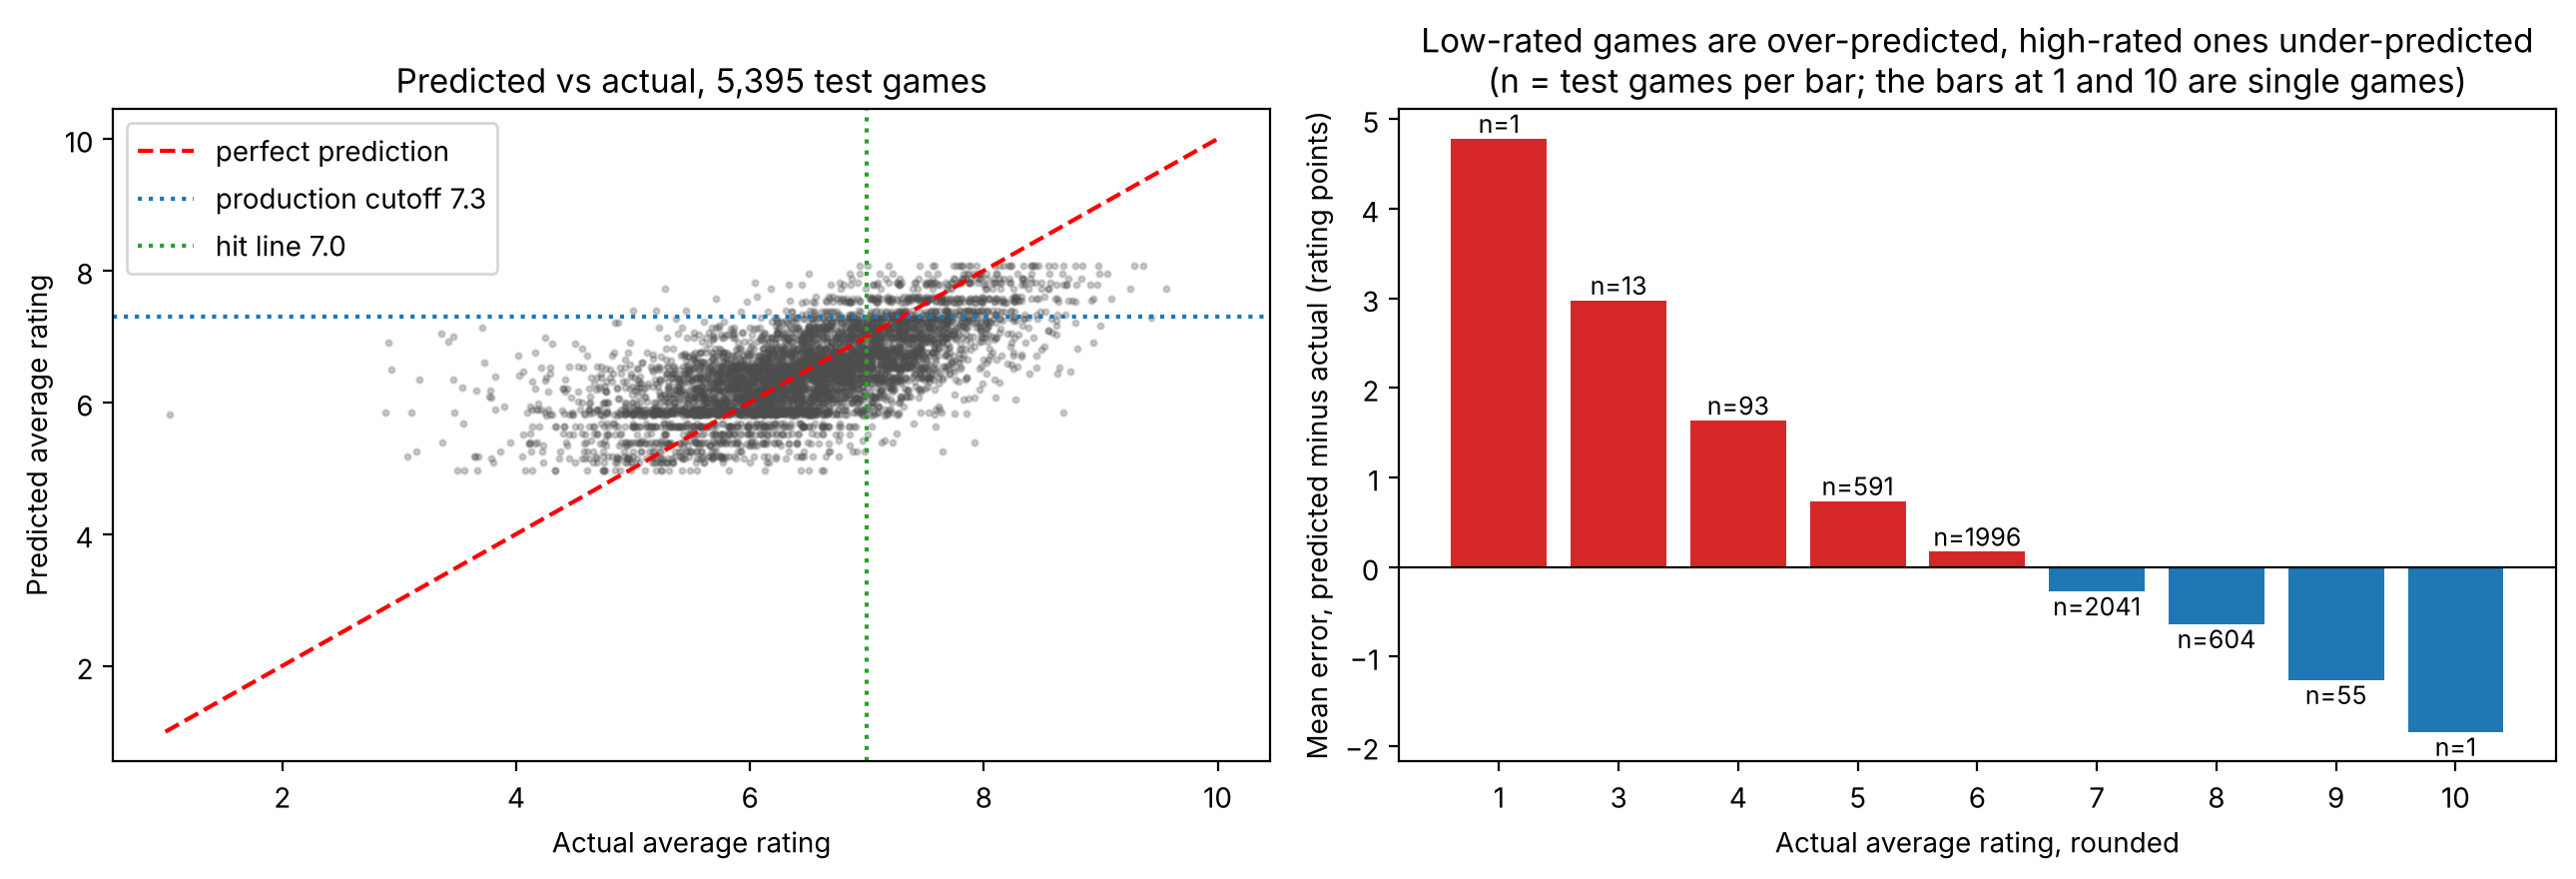

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Figure: the model pulls every game toward the middle; reviewed and edited by Andrew Reicin.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(check["average"], check["predicted"], s=4, alpha=0.25, color="0.3")
axes[0].plot([1, 10], [1, 10], color="red", linestyle="--", label="perfect prediction")
axes[0].axhline(y=best_cut, color="tab:blue", linestyle=":", label=f"production cutoff {best_cut}")
axes[0].axvline(x=HIT, color="tab:green", linestyle=":", label=f"hit line {HIT}")
axes[0].set_xlabel("Actual average rating")
axes[0].set_ylabel("Predicted average rating")
axes[0].set_title(f"Predicted vs actual, {len(check):,} test games")
axes[0].legend(loc="upper left")

colors = ["tab:red" if v > 0 else "tab:blue" for v in by_rating["error"]]
axes[1].bar(by_rating.index.astype(int).astype(str), by_rating["error"], color=colors)
axes[1].axhline(y=0, color="black", linewidth=0.8)
for i, (err, n) in enumerate(zip(by_rating["error"], by_rating["games"])):
    axes[1].text(i, err, f"n={n}", ha="center", va="bottom" if err > 0 else "top", fontsize=9)
axes[1].set_xlabel("Actual average rating, rounded")
axes[1].set_ylabel("Mean error, predicted minus actual (rating points)")
axes[1].set_title("Low-rated games are over-predicted, high-rated ones under-predicted\n(n = test games per bar; the bars at 1 and 10 are single games)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "07_errors_by_rating.png"), dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Step 2c: the ten largest misses; reviewed and edited by Andrew Reicin.
cols = ["name", "yearpublished", "maxplaytime", "minage", "n_mechanics", "users_rated", "average", "predicted"]
check.sort_values("abs_error", ascending=False)[cols].head(10).round(2)

,name,yearpublished,maxplaytime,minage,n_mechanics,users_rated,average,predicted
12558,Oneupmanship: Mine's Bigger,2013.0,90.0,12.0,5.0,75,1.04,5.82
14669,The Civil War,1991.0,1200.0,12.0,3.0,52,2.91,6.91
15219,New Earth,2016.0,120.0,10.0,5.0,47,3.36,7.05
14658,Warmaster Chess 2000,1998.0,60.0,10.0,1.0,52,2.93,6.49
11272,Big Time Soccer,2016.0,60.0,10.0,2.0,94,3.46,6.99
17040,"Operation Elope, 1918-1919",2001.0,240.0,12.0,3.0,34,3.42,6.92
7259,Nero,2002.0,100.0,12.0,6.0,222,3.71,7.13
10598,Pug You!,2018.0,45.0,16.0,2.0,107,3.17,6.35
1477,Bingo,1530.0,60.0,5.0,3.0,2282,2.88,5.84
13462,Cardiceo,2016.0,60.0,10.0,2.0,64,3.46,6.35


In [ ]:
# [AI-assisted] Claude (Opus 5.5), 2026-11-09. Step 2d: the hits the model catches vs the hits it misses; reviewed and edited by Andrew Reicin.
check["hit"] = np.where(check["average"] >= HIT, 1, 0)
check["made"] = np.where(check["predicted"] >= best_cut, 1, 0)
hits = check[check["hit"] == 1].copy()
hits["outcome"] = np.where(hits["made"] == 1, "hit caught", "hit missed")
print(hits["outcome"].value_counts(), "\n")
hits.groupby("outcome")[["yearpublished", "maxplaytime", "minage", "n_mechanics", "users_rated", "average"]].median().round(1)

outcome
hit missed    1117
hit caught     405
Name: count, dtype: int64 



,yearpublished,maxplaytime,minage,n_mechanics,users_rated,average
outcome,,,,,,
hit caught,2019.0,120.0,13.0,6.0,189.0,7.8
hit missed,2015.0,60.0,12.0,3.0,282.0,7.3


- Predictions are pulled toward the middle: low-rated games too high, high-rated games too low.
- Larger errors for games with fewer than 150 ratings (0.58 vs 0.46) and games before 1970 (0.75); wargames are about the same as the rest.
- Hits caught are mostly recent, long games with many mechanics; hits missed are shorter and lighter.
- Possible next step: a pre-release feature such as the designer's or publisher's track record.